In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
# Load data
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df['diagnosis'] = df['target'].map({0: 'malignant', 1: 'benign'})
df = df.drop(columns='target')
# Make the dataset 'messy' (do not modify)
rng = np.random.default_rng(42)
for col in ['mean radius', 'mean texture', 'mean area', 'worst perimeter']:
 idx = rng.choice(df.index, size=30, replace=False)
 df.loc[idx, col] = np.nan
df = pd.concat([df, df.sample(10, random_state=1)], ignore_index=True)

In [ ]:
# Display the first 5 rows
display(df.head())

# Display the last 5 rows
display(df.tail())


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
574,16.16,21.54,106.20,NaN,0.10080,0.12840,0.10430,0.05613,0.2160,0.05891,...,31.68,129.70,1175.0,0.13950,0.3055,0.2992,0.13120,0.3480,0.07619,malignant
575,19.19,15.94,126.30,1157.0,0.08694,0.11850,0.11930,0.09667,0.1741,0.05176,...,17.81,146.60,1495.0,0.11240,0.2016,0.2264,0.17770,0.2443,0.06251,malignant
576,18.08,21.84,117.40,1024.0,0.07371,0.08642,0.11030,0.05778,0.1770,0.05340,...,24.70,129.10,1228.0,0.08822,0.1963,0.2535,0.09181,0.2369,0.06558,malignant
577,10.48,NaN,66.72,337.7,0.10700,0.05971,0.04831,0.03070,0.1737,0.06440,...,29.46,73.68,402.8,0.15150,0.1026,0.1181,0.06736,0.2883,0.07748,benign
578,14.53,13.98,93.86,644.2,0.10990,0.09242,0.06895,0.06495,0.1650,0.06121,...,16.93,103.10,749.9,0.13470,0.1478,0.1373,0.10690,0.2606,0.07810,benign


In [ ]:
print(df.shape)
print(df.dtypes)

print(df['diagnosis'].value_counts())
print(df['diagnosis'].value_counts(normalize=True) * 100)

print("Classes are not balanced.")



(579, 31)
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symm

In [ ]:
m = pd.DataFrame({
    'Count': df.isnull().sum(),
    'Percent': df.isnull().mean() * 100
})
display(m[m['Count'] > 0])


,Count,Percent
mean radius,30,5.181347
mean texture,31,5.354059
mean area,31,5.354059
worst perimeter,30,5.181347


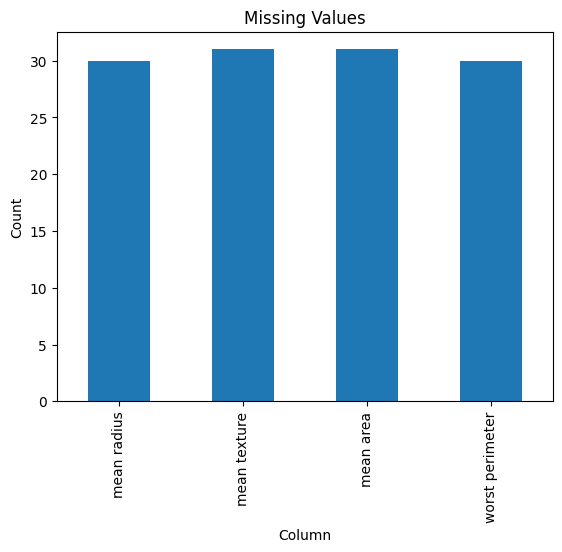

In [ ]:
df.isnull().sum()[df.isnull().sum() > 0].plot(kind='bar')
plt.title('Missing Values')
plt.xlabel('Column')
plt.ylabel('Count')
plt.show()


In [ ]:
df_clean = df.copy()

cols = ['mean radius', 'mean texture', 'mean area', 'worst perimeter']

for c in cols:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())

print("Missing values:", df_clean.isnull().sum().sum())


Missing values: 0


In [ ]:
print("Duplicates:", df.duplicated().sum())
print("Before:", df_clean.shape)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("After:", df_clean.shape)



Duplicates: 10
Before: (579, 31)
After: (569, 31)


In [ ]:
cols = ['mean radius', 'mean area', 'mean texture']

table = df_clean[cols].agg(
    ['mean', 'median', 'std', 'min', 'max']
).T

display(table.round(2))


,mean,median,std,min,max
mean radius,14.13,13.46,3.43,6.98,28.11
mean area,652.66,555.90,348.73,143.50,2501.00
mean texture,19.24,18.74,4.21,9.71,39.28


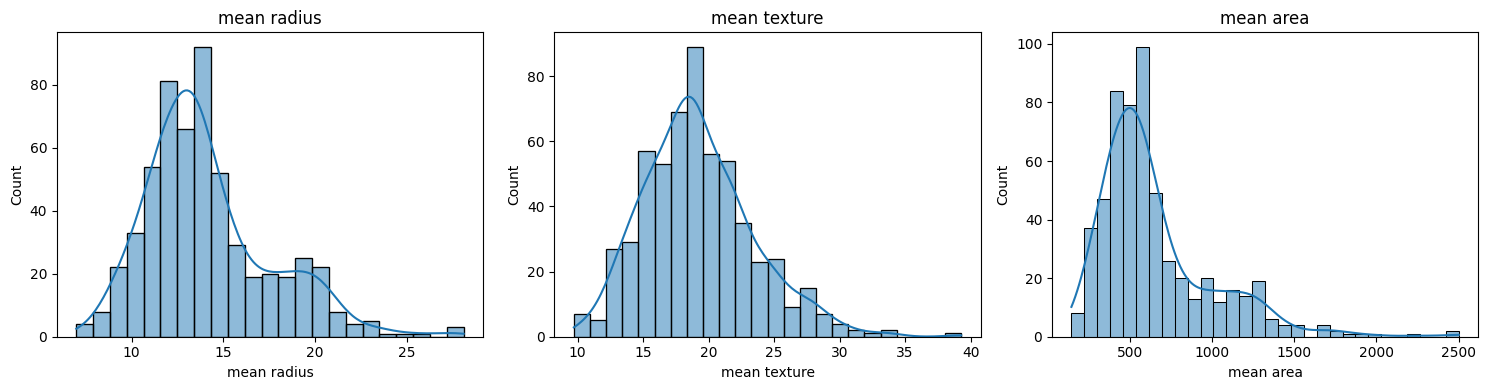

In [ ]:
features = ['mean radius', 'mean texture', 'mean area']

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for i, c in enumerate(features):
    sns.histplot(df_clean[c], kde=True, ax=ax[i])
    ax[i].set_title(c)
    ax[i].set_xlabel(c)
    ax[i].set_ylabel('Count')

plt.tight_layout()
plt.show()


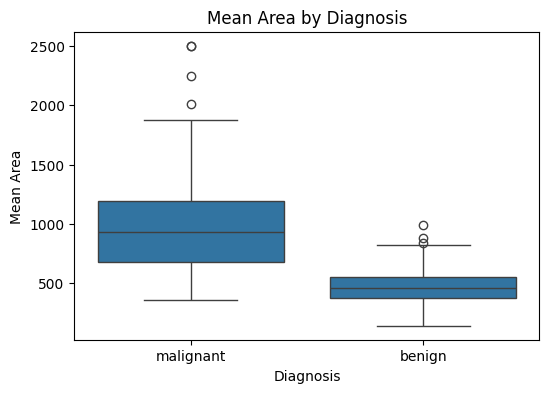

In [ ]:
plt.figure(figsize=(6, 4))

sns.boxplot(data=df_clean, x='diagnosis', y='mean area')

plt.title('Mean Area by Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Mean Area')
plt.show()


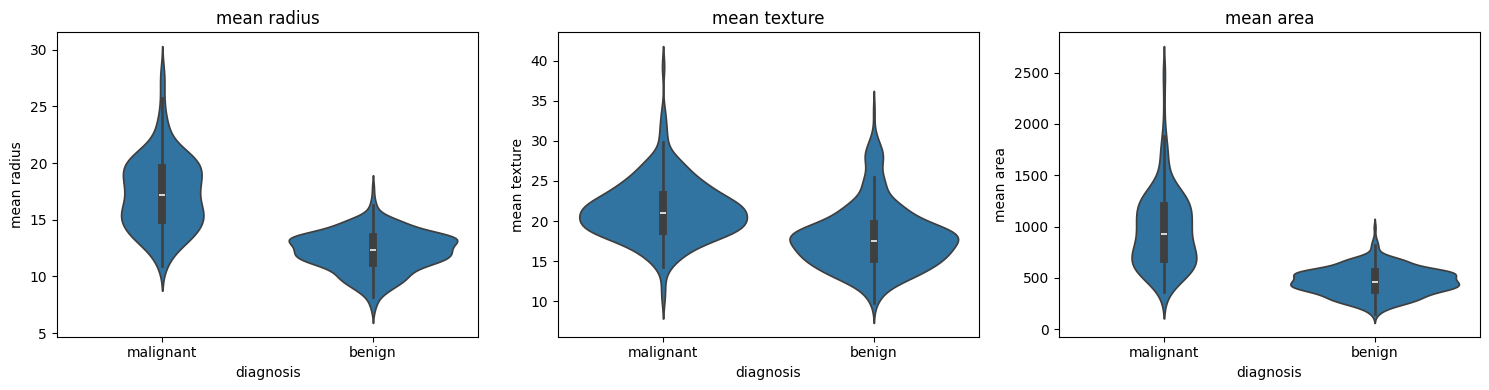

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for i, c in enumerate(features):
    sns.violinplot(data=df_clean, x='diagnosis', y=c, ax=ax[i])
    ax[i].set_title(c)

plt.tight_layout()
plt.show()


In [ ]:
mean_cols = [c for c in df_clean.columns if c.startswith('mean ')]

means = df_clean.groupby('diagnosis')[mean_cols].mean()

display(means.round(2))


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
diagnosis,,,,,,,,,,
benign,12.23,17.96,78.08,466.42,0.09,0.08,0.05,0.03,0.17,0.06
malignant,17.33,21.38,115.37,966.28,0.10,0.15,0.16,0.09,0.19,0.06


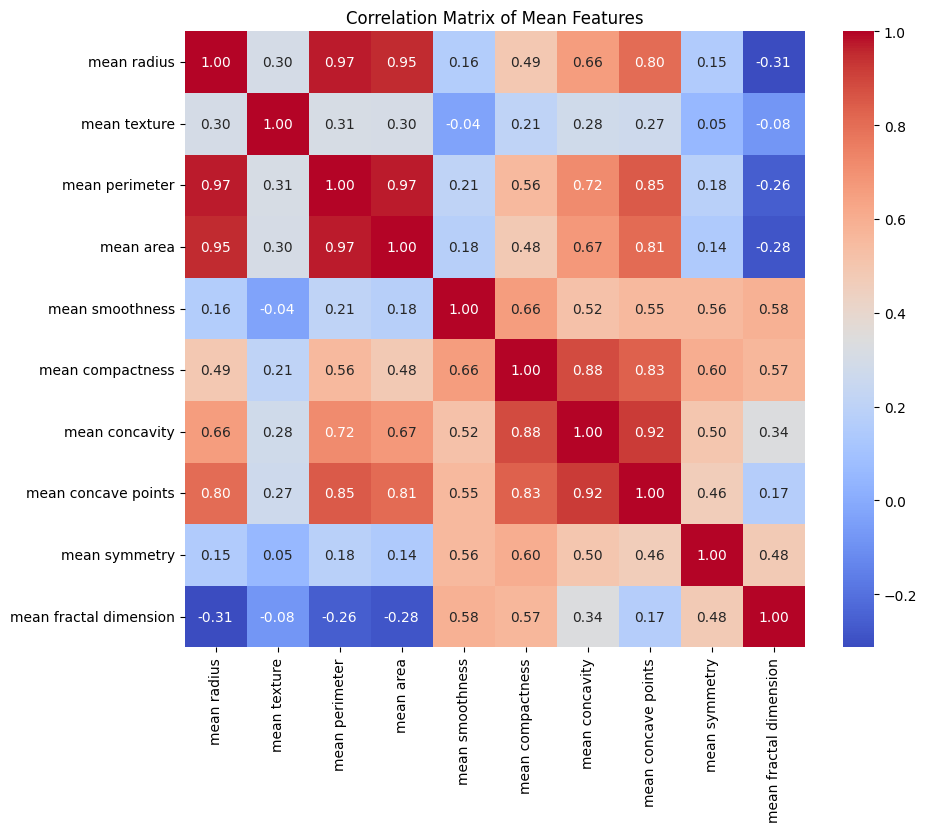

In [ ]:
corr = df_clean[mean_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Matrix of Mean Features')
plt.show()


In [ ]:
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if corr.iloc[i, j] > 0.9:
            print(corr.columns[i], '--', corr.columns[j],
                  ':', round(corr.iloc[i, j], 2))


mean radius -- mean perimeter : 0.97
mean radius -- mean area : 0.95
mean perimeter -- mean area : 0.97
mean concavity -- mean concave points : 0.92


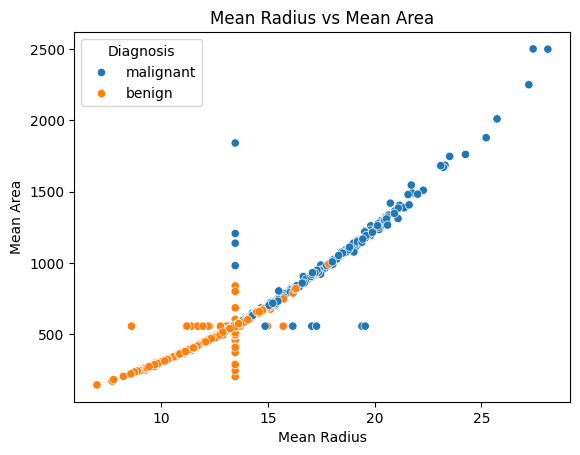

In [ ]:
sns.scatterplot(
    data=df_clean,
    x='mean radius',
    y='mean area',
    hue='diagnosis'
)

plt.title('Mean Radius vs Mean Area')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Area')
plt.legend(title='Diagnosis')
plt.show()
